# TP 4 - Assembler et entraîner le modèle complet

Tokens + positions -> attention multi-têtes -> LayerNorm et MLP -> 4 blocs résiduels -> unembedding

## Étape 0 - Préparer le notebook

In [1]:
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
from urllib.request import urlretrieve

# hyperparamètres
batch_size = 16        # B
block_size = 32        # T maximum
max_iters = 5000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 64            # C
n_head = 4
n_layer = 4
dropout = 0.0

assert n_embd % n_head == 0
torch.manual_seed(1337)
print(device)

cpu


In [2]:
# partie reprise du TP 1
url = ("https://raw.githubusercontent.com/karpathy/"
       "char-rnn/master/data/tinyshakespeare/input.txt")
urlretrieve(url, "input.txt")
with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

# vocabulaire de caractères
chars = sorted(list(set(text)))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: ''.join([itos[i] for i in ids])

# 90% train, 10% validation
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]


def get_batch(split):
    source = train_data if split == "train" else val_data
    starts = torch.randint(len(source) - block_size, (batch_size,))
    x = torch.stack([source[i : i + block_size] for i in starts])          # (B, T)
    y = torch.stack([source[i + 1 : i + block_size + 1] for i in starts])  # (B, T)
    return x.to(device), y.to(device)      # sur le même appareil que le modèle


print(len(text), "caractères | vocabulaire :", vocab_size)

1115394 caractères | vocabulaire : 65


**d_h = n_embd / n_head** = 64 / 4 = 16.

**Tokens par batch :** 16 × 32 = 512.

**Sur CPU,** on réduit d'abord `max_iters` (par exemple 200) pour vérifier que tout tourne, puis `eval_iters`.

## Étape 1 - Une tête d'attention

In [3]:
class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        # masque triangulaire : pas un paramètre, mais suit le modèle sur GPU
        self.register_buffer(
            'tril', torch.tril(torch.ones(block_size, block_size))
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape                                  # (B, T, C)
        k, q = self.key(x), self.query(x)                  # (B, T, d_h)
        wei = q @ k.transpose(-2, -1) * k.size(-1)**-0.5   # (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))  # futur masqué
        wei = F.softmax(wei, dim=-1)                       # (B, T, T)
        wei = self.dropout(wei)
        v = self.value(x)                                  # (B, T, d_h)
        return wei @ v                                     # (B, T, d_h)

**Pourquoi `k.size(-1)` plutôt que C ?** La variance du produit scalaire dépend de la dimension des vecteurs comparés, soit d_h = 16, et non C = 64.

**Pourquoi tronquer `tril[:T, :T]` ?** La séquence peut être plus courte que `block_size`, par exemple au début de la génération. Le masque doit avoir la même taille que `wei`.

## Étape 2 - Plusieurs têtes

In [4]:
class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([
            Head(head_size) for _ in range(num_heads)
        ])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # on colle les sorties des têtes : 4 x (B, T, 16) -> (B, T, 64)
        out = torch.cat(
            [h(x) for h in self.heads], dim=-1
        )
        # la projection mélange les informations des têtes : (B, T, 64)
        return self.dropout(self.proj(out))

**Pourquoi concaténer sur la dernière dimension ?** Chaque tête produit des composantes pour les mêmes tokens. On les met bout à bout sans toucher au batch ni au temps.

**Et si `n_embd` n'était pas divisible par `n_head` ?** La concaténation ne redonnerait pas `n_embd` (avec 5 têtes : 5 × 12 = 60 au lieu de 64) et `proj` provoquerait une erreur de forme.

## Étape 3 - Un bloc

In [5]:
class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4*n_embd),    # (B, T, 4C)
            nn.ReLU(),
            nn.Linear(4*n_embd, n_embd),    # (B, T, C)
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):                   # (B, T, C)
        x = x + self.sa(self.ln1(x))        # communication entre tokens
        x = x + self.ffwd(self.ln2(x))      # calcul sur chaque token
        return x                            # (B, T, C)

**Ordre des opérations :** LayerNorm, puis attention ou MLP, puis addition à l'entrée (pré-norm).

**Communication** = l'attention, qui échange de l'information entre positions. **Calcul** = le feed-forward, appliqué à chaque token séparément.

## Étapes 4, 5 et 6 - Le modèle : couches, passage avant et génération

In [6]:
class BigramLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(
            vocab_size, n_embd          # identité du caractère
        )
        self.position_embedding_table = nn.Embedding(
            block_size, n_embd          # place dans le contexte
        )
        self.blocks = nn.Sequential(*[
            Block(n_embd, n_head=n_head)
            for _ in range(n_layer)
        ])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)   # vers les logits

    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok_emb = self.token_embedding_table(idx)       # (B, T, C)
        pos = torch.arange(T, device=idx.device)        # (T,)
        pos_emb = self.position_embedding_table(pos)    # (T, C)

        x = tok_emb + pos_emb                           # (B, T, C)
        x = self.blocks(x)                              # (B, T, C)
        x = self.ln_f(x)                                # (B, T, C)
        logits = self.lm_head(x)                        # (B, T, vocab_size)

        if targets is None:
            loss = None
        else:
            logits = logits.reshape(B*T, vocab_size)    # (B*T, vocab_size)
            targets = targets.reshape(B*T)              # (B*T,)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]             # on garde la fin du contexte
            logits, _ = self(idx_cond)                  # (B, T, vocab_size)

            logits = logits[:, -1, :]                   # (B, vocab_size)
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(               # (B, 1)
                probs, num_samples=1
            )
            idx = torch.cat((idx, idx_next), dim=1)     # (B, T+1)
        return idx

**Dimensions des trois matrices :**
- embedding de token : (vocab_size, n_embd), soit (65, 64) ;
- embedding de position : (block_size, n_embd), soit (32, 64) ;
- `lm_head` (unembedding) : de n_embd vers vocab_size, poids stockés en (65, 64), plus un biais.

**Pourquoi `lm_head` n'est-il plus confondu avec l'embedding ?** Au TP 1, une seule table C × C donnait directement les logits. Ici l'embedding produit un vecteur dense, enrichi par les blocs, et `lm_head` le convertit ensuite en scores.

**Quelle règle de broadcasting permet l'addition ?** Les dimensions sont comparées de droite à gauche. `pos_emb` (T, C) reçoit une dimension batch implicite et s'ajoute à chacune des B séquences.

**Pourquoi ne pas aplatir les logits à la génération ?** Il n'y a pas de loss, et on a besoin de la dimension temps pour prendre le dernier pas.

**Pourquoi `@torch.no_grad()` ?** On ne fait pas de rétropropagation : cela économise mémoire et temps.

**Pourquoi `multinomial` plutôt que `argmax` ?** Le tirage donne un texte varié. `argmax` est déterministe et tend à répéter les mêmes suites en boucle.

## Étape 7 - Évaluer

In [7]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()                   # désactive le dropout
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()                  # retour en mode entraînement
    return out

**Pourquoi `model.eval()` puis `model.train()` ?** `eval()` désactive le dropout pour mesurer un résultat stable ; `train()` le réactive ensuite.

**Si la loss train baisse mais que la loss validation remonte ?** C'est du sur-apprentissage : le modèle mémorise le texte d'entraînement. On peut augmenter le dropout, s'arrêter plus tôt, réduire le modèle ou ajouter des données.

## Test rapide avant l'entraînement

In [8]:
model = BigramLanguageModel().to(device)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M de paramètres")

xb, yb = get_batch('train')
logits, loss = model(xb, yb)
print(xb.shape, logits.shape, loss.item())     # loss de départ proche de log(vocab_size)

# vérification du masque : changer le dernier token ne change pas les positions d'avant
model.eval()
xb2 = xb.clone()
xb2[:, -1] = (xb2[:, -1] + 1) % vocab_size
with torch.no_grad():
    l1, _ = model(xb)
    l2, _ = model(xb2)
print(torch.allclose(l1[:, :-1], l2[:, :-1]))  # doit afficher True
_ = model.train()

0.209729 M de paramètres
torch.Size([16, 32]) torch.Size([512, 65]) 4.381542205810547
True


In [9]:
# texte avant entraînement
context = torch.zeros((1, 1), dtype=torch.long, device=device)
model.eval()
texte_avant = decode(model.generate(context, max_new_tokens=500)[0].tolist())
model.train()
print(texte_avant)


.mBP.A XPjQOl;-QfYbxwgHgyvp'VE,nqfoaUorzzcCTfJAqzXFyp?lgsuNs:GriKfXJsFN'r!QrbFcUWWQ
:KXN.;PreFoeIWszlJXFLKYdMcUNUNYRK,
RysopWvfmYxcjeRJJcuAfJDRew
LOvzFV;3XNnokWoo?derEahBRoHQWgoKkfoJAdVkK-TEUKOJOeLfVvodJLR;eXbcXJJAJpciiFOzzpbsDjcWwTEV&,ppJE,$&reszTd??VcN?deg$NUZIc?&?drSpZgN
FRVfwgretfRHbuHYLkgKzewY'emQkcbseMLFEXptcp3EpqcVqL'kaeXuNp3Jeyyje!JJSUzIAkPRaKFb'y!rqRsnzXm:J?xFpimio,nV&Xm?iNwq3ik
poMnD$tz?3D!RUpD,:AGek,cqgcpquNLKV;MMBOKE;OgbsnibW.XHcpKphBcmcpb,Aebm3$Xbpl!fNq&p3!3aXqhDe?! YEy p3pDtgm
ht.l


## Étape 8 - Entraîner

In [10]:
optimizer = torch.optim.AdamW(
    model.parameters(), lr=learning_rate
)
historique = []

for iteration in range(max_iters):
    # point de suivi régulier (et à la dernière itération)
    if iteration % eval_interval == 0 or iteration == max_iters - 1:
        pertes = estimate_loss()
        historique.append({"iteration": iteration, **pertes})
        print(f"{iteration:5d} | train {pertes['train']:.3f} | val {pertes['val']:.3f}")

    xb, yb = get_batch('train')
    _, loss = model(xb, yb)                  # forward
    optimizer.zero_grad(set_to_none=True)    # remise à zéro des gradients
    loss.backward()                          # rétropropagation
    optimizer.step()                         # mise à jour

    0 | train 4.412 | val 4.403
  100 | train 2.649 | val 2.653
  200 | train 2.494 | val 2.490
  300 | train 2.383 | val 2.399
  400 | train 2.321 | val 2.314
  500 | train 2.268 | val 2.273
  600 | train 2.197 | val 2.208
  700 | train 2.155 | val 2.175
  800 | train 2.121 | val 2.147
  900 | train 2.095 | val 2.120
 1000 | train 2.065 | val 2.117
 1100 | train 2.028 | val 2.074
 1200 | train 2.002 | val 2.067
 1300 | train 1.991 | val 2.052
 1400 | train 1.967 | val 2.032
 1500 | train 1.943 | val 2.021
 1600 | train 1.933 | val 2.004
 1700 | train 1.899 | val 1.995
 1800 | train 1.894 | val 1.970
 1900 | train 1.877 | val 1.971
 2000 | train 1.870 | val 1.966
 2100 | train 1.859 | val 1.966
 2200 | train 1.841 | val 1.951
 2300 | train 1.826 | val 1.958
 2400 | train 1.815 | val 1.936
 2500 | train 1.810 | val 1.941
 2600 | train 1.803 | val 1.941
 2700 | train 1.789 | val 1.936
 2800 | train 1.772 | val 1.926
 2900 | train 1.768 | val 1.915
 3000 | train 1.759 | val 1.912
 3100 | 

## Étape 9 - Générer et expérimenter

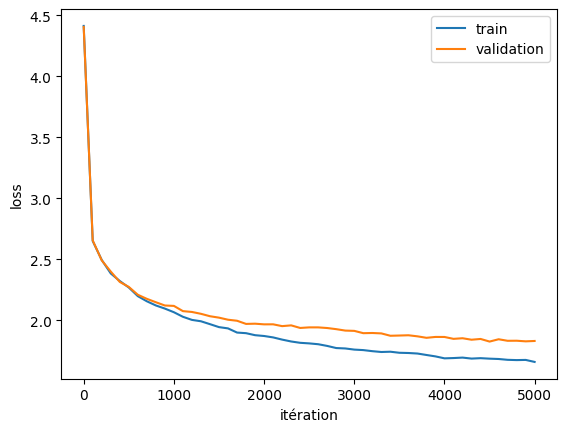

In [11]:
# courbes des losses
its = [h["iteration"] for h in historique]
plt.plot(its, [h["train"] for h in historique], label="train")
plt.plot(its, [h["val"] for h in historique], label="validation")
plt.xlabel("itération")
plt.ylabel("loss")
plt.legend()
plt.show()

In [12]:
# 2000 caractères après entraînement
context = torch.zeros((1, 1), dtype=torch.long, device=device)
model.eval()
result = model.generate(context, max_new_tokens=2000)
model.train()
print(decode(result[0].tolist()))


I well:
The drie identy from ineful lord:
Deful be datcher: beente with Tyblusel
Being long he emisal of when, my lord.
Whath is we like: ildrow, staker,
I being Anurking friends and blookizens him,
Sir; die no and back to the king;
Then angering gual.

ANGELLIZABETH:
How sic yea, appety.

ROMEO:
With aless my lord, my life?
But Ropt out his disprice
With his sence!

SLAURER:
Achart their feor pance, thinks:
Sure hame woundemnic of the fire--Dorshy Itay like all times.

Fiaul hear he the bittrawnes; we weegnts;
Wich the bowere seee ever servering,
Show an marre's rature, ans templixtable.
Why to me one if thing so, I'll king--ala'tbering,
To, exponest by pricereces
That wo he I would Soravingens' so to exdisce
Asomake you go, thou
all benehalt's tell tier: Lay's git pain.
I'll you, beseech, I they know take your gentans,
And Magre thy lex he agre
Of cale him in by serve,.

Fith my lord?
Hewisnower comented but, will with me:' us alicying of reshall,
I say, nop, good striaw, nor shall 

### Expériences

On change **un seul réglage à la fois**, avec le même nombre d'itérations pour tous les essais.

In [13]:
iters_exp = 2000     # plus court, pour comparer rapidement


def experience(bs=32, tetes=4, drop=0.0):
    global model, block_size, n_head, dropout
    ancien = model, block_size, n_head, dropout      # on sauvegarde
    block_size, n_head, dropout = bs, tetes, drop

    torch.manual_seed(1337)
    model = BigramLanguageModel().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    for _ in range(iters_exp):
        xb, yb = get_batch('train')
        _, loss = model(xb, yb)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
    pertes = estimate_loss()

    model, block_size, n_head, dropout = ancien      # on remet comme avant
    return pertes


essais = {
    "référence (T=32, 4 têtes)": {},
    "block_size = 16": {"bs": 16},
    "block_size = 64": {"bs": 64},
    "1 tête": {"tetes": 1},
    "dropout = 0.2": {"drop": 0.2},
}
resultats = {}
for nom, reglage in essais.items():
    resultats[nom] = experience(**reglage)
    p = resultats[nom]
    print(f"{nom:28s} | train {p['train']:.3f} | val {p['val']:.3f} | écart {p['val'] - p['train']:.3f}")

référence (T=32, 4 têtes)    | train 1.871 | val 1.964 | écart 0.093
block_size = 16              | train 1.931 | val 2.027 | écart 0.095
block_size = 64              | train 1.831 | val 1.940 | écart 0.109
1 tête                       | train 1.852 | val 1.962 | écart 0.110
dropout = 0.2                | train 1.969 | val 2.027 | écart 0.058


### Analyse

1. **Texte avant / après** (mots, ponctuation, noms de personnages) : avant l'entraînement, c'est une suite de caractères au hasard (majuscules, ponctuation, `$`, chiffre `3`), sans phrases lisibles. Après, le texte ressemble à une pièce de théâtre : des noms en majuscules suivis de `:` (`ROMEO:`, `RICHARD:`, mais aussi des noms inventés comme `BUGILIUCK:`), des retours à la ligne et de vrais mots (`my lord`, `the king`, `brother`). Il reste des mots inventés (`templixtable`, `pricereces`) et les phrases n'ont pas de sens.

2. **Losses train / validation** : on part de 4,412 / 4,403, un peu au-dessus de ln(65) ≈ 4,17 (la loss d'un choix uniforme entre les 65 caractères), et on finit à 1,658 / 1,830. La baisse est très rapide au début (2,649 / 2,653 dès l'itération 100), puis lente. L'écart entre validation et train passe de 0,005 à l'itération 500 à 0,172 à la fin. La validation continue globalement de baisser (les petites remontées viennent surtout des batchs tirés au hasard pour l'évaluation) : pas de vrai sur-apprentissage, même si l'écart grandit.

3. **`block_size` 16 contre 64** : un contexte plus long donne plus d'information, mais change aussi le nombre de tokens par batch. Observé : la loss de validation vaut 2,027 avec 16, 1,964 avec 32 et 1,940 avec 64. Le contexte long fait mieux, mais un batch contient alors 1024 tokens contre 256 : en 2000 itérations, le modèle voit 4 fois plus de texte. Le gain ne vient donc pas forcément du seul contexte.

4. **1 tête contre 4** (même `n_embd`) : plusieurs têtes peuvent suivre des relations différentes. Observé : validation 1,962 avec 1 tête et 1,964 avec 4, soit pratiquement aucune différence. La loss train est un peu plus basse avec 1 tête (1,852 contre 1,871), sans effet sur la validation. Les matrices Q, K et V ont au total le même nombre de paramètres dans les deux cas. Avec ce petit modèle et un seul essai, on ne peut pas conclure que 4 têtes sont meilleures.

5. **Dropout** : utile surtout si la validation s'écarte nettement du train. Observé : avec 0,2, l'écart diminue (0,058 contre 0,093), mais les deux losses sont moins bonnes (train 1,969, validation 2,027). Le sur-apprentissage étant faible ici, on garde `dropout = 0.0`.

**Limite de la comparaison :** les expériences durent 2000 itérations (contre 5000 pour le modèle principal), avec un seul essai par réglage. On les compare entre elles, pas avec le résultat final.

## Bilan des quatre TP

| Classe | Notion du cours | Rôle |
|---|---|---|
| `Head` | self-attention (TP 2) | crée le contexte entre tokens |
| `MultiHeadAttention` | attention multi-têtes | combine plusieurs relations |
| `FeedForward` | MLP (TP 3) | transforme chaque token séparément |
| `Block` | résiduel et LayerNorm (TP 3) | alterne communication et calcul |
| `BigramLanguageModel` | embeddings et unembedding (TP 1) | assemble tout et produit les logits |

**Quelle brique crée le contexte ?** L'attention.

**Laquelle transforme un token ?** Le feed-forward.

**Laquelle produit les logits ?** `lm_head`.

**Où la loss agit-elle ?** Elle est calculée sur la sortie, mais la rétropropagation envoie son gradient à tous les paramètres : embeddings, Q, K, V, projections, MLP, LayerNorm et `lm_head`.